# Empirical Stability Certificate Analysis

Tests the stability theory from the paper: computes margins $\Delta$, erosion $\rho$, and stability ratios $R = \rho/\Delta$ for the base and adapter-corrected embeddings.

**Requires**: cached table embeddings in `CACHE_ROOT`, pre-trained adapter checkpoint, and a loaded model for query encoding (or cached query embeddings).

**Tables produced**: A (margin distribution), B (certification rates), C (adapter effect), D (Proposition 3 bound check).

**Figures produced**: depth monotonicity (cert rate vs K) and R-value CDF with retrieval failure overlay.

In [1]:
import os, sys, gc, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import scipy.sparse
import torch
from collections import defaultdict
from pathlib import Path
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

REPO_ROOT = '/home/bhandk/Table Representation Retrieval'
sys.path.insert(0, REPO_ROOT)

from utils.cache_embedding import cache_exists_for_model, load_cache_for_model
from utils.core import CACHE_ROOT, FORMATS_17
from utils.Adapter import HierDenseAdapter, HierSparseAdapter, FMT2IDX, REPRESENTATIVE_ORDER
from utils.core import SPLADE_TOPK, _topk_dense_to_sparse

print('CACHE_ROOT:', CACHE_ROOT)
print('FORMATS_17:', FORMATS_17)

CACHE_ROOT: /data/Kushal/UniversalRetrieval_data/emb_cache
FORMATS_17: ['pipe_serialized', 'token_serialized', 'space_serialized', 'csv', 'tsv', 'html', 'markdown', 'latex', 'dict', 'json', 'xml', 'shuffled_rows', 'shuffled_cols', 'transpose', 'mschema', 'macschema', 'ddl']


/home/bhandk/miniconda3/envs/TableRAG/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

Set `MODEL_NAME` and `DATASETS` below. `ADAPTER_DATE` selects which trained adapter to load.

In [2]:
# ─── User-configurable ───────────────────────────────────────────────────────
MODEL_NAME   = 'mpnet'                  # miniLM | mdbr | mpnet | bge | qwen0.6B | reasonir | splade
DATASETS     = ['WTQ', 'WIKISQL', 'NQ'] # subset to ['WTQ'] for a quick run
K_VALUES     = [1, 5, 10]               # Recall@K depths to certify
ADAPTER_DATE = '2026-09-12'             # '2026-09-12' (subset) or '2026-09-17' (all)
ADAPTER_SUBSET = True                   # True → subset adapter; False → full-dataset adapter
MAX_QUERIES  = 100                      # None → all queries; int → cap per dataset (for quick verification)

# ─── Derived paths ───────────────────────────────────────────────────────────
DATA_ROOT   = '/data/Kushal/UniversalRetrieval_data'
QUESTIONS_PATH = f'{DATA_ROOT}/dataset_all/new_all_questions_dict_wtq_nqt_wikisql.pkl'

if ADAPTER_SUBSET:
    ADAPTER_PATH = f'{DATA_ROOT}/{ADAPTER_DATE}/centroid_adapter_subset_dataset/{MODEL_NAME}/adapter.pt'
else:
    ADAPTER_PATH = f'{DATA_ROOT}/{ADAPTER_DATE}/centroid_adapter/{MODEL_NAME}/adapter.pt'

QUERY_CACHE_DIR = f'{DATA_ROOT}/query_emb_cache/{MODEL_NAME}'
RESULTS_DIR     = f'{REPO_ROOT}/data/stability_analysis/{MODEL_NAME}'
os.makedirs(QUERY_CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

IS_SPLADE = (MODEL_NAME == 'splade')
DELTA_ALL = 0.01   # Proposition 3 premise threshold (from HierCfg.delta_all)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Model: {MODEL_NAME}  |  Device: {DEVICE}')
print(f'Adapter: {ADAPTER_PATH}')
print(f'Adapter exists: {os.path.exists(ADAPTER_PATH)}')
print(f'MAX_QUERIES: {MAX_QUERIES}')


Model: mpnet  |  Device: cuda
Adapter: /data/Kushal/UniversalRetrieval_data/2026-09-12/centroid_adapter_subset_dataset/mpnet/adapter.pt
Adapter exists: True
MAX_QUERIES: 100


## Helper: Batch Top-3 Mean Scoring

Computes the table-level score used for retrieval (`score_top3_chunk_mean`) for **all queries at once** via a batched matrix multiply, which is much faster than one query at a time.

In [3]:
def group_chunks_by_table(chunk_ids):
    """Returns {table_id: [chunk_indices, ...]}, sorted table_ids list."""
    tbl2idx = defaultdict(list)
    for i, did in enumerate(chunk_ids):
        tbl2idx[did.rsplit('::', 1)[0]].append(i)
    table_ids = sorted(tbl2idx.keys())
    return tbl2idx, table_ids


def compute_table_scores(
    chunk_ids, chunk_emb, Q_matrix,
    q_batch=128, c_batch=4096,
):
    """
    Compute top-3-mean table scores for ALL queries at once.

    Args
    ----
    chunk_ids  : list[str]   '{table_id}::{chunk_idx}' strings
    chunk_emb  : (N_c, D)   dense numpy array or scipy CSR
    Q_matrix   : (n_q, D)   float32 query embeddings

    Returns
    -------
    table_ids    : list[str]  sorted unique table IDs
    table_scores : (n_tables, n_queries) float32
    """
    is_sp = scipy.sparse.issparse(chunk_emb)
    n_chunks = chunk_emb.shape[0]
    n_queries = Q_matrix.shape[0]

    tbl2idx, table_ids = group_chunks_by_table(chunk_ids)
    n_tables = len(table_ids)

    # Pre-build chunk→table mapping as array for vectorised top3 later
    table_scores = np.zeros((n_tables, n_queries), dtype=np.float32)
    tid_to_tidx = {t: i for i, t in enumerate(table_ids)}

    for q_start in range(0, n_queries, q_batch):
        q_end = min(q_start + q_batch, n_queries)
        Qb    = np.ascontiguousarray(Q_matrix[q_start:q_end], dtype=np.float32)  # (bq, D)

        # chunk_scores_b : (n_chunks, bq)
        if is_sp:
            cs_b = np.asarray(chunk_emb.dot(Qb.T), dtype=np.float32)
        else:
            bq   = q_end - q_start
            cs_b = np.zeros((n_chunks, bq), dtype=np.float32)
            for c0 in range(0, n_chunks, c_batch):
                c1   = min(c0 + c_batch, n_chunks)
                blk  = np.asarray(chunk_emb[c0:c1], dtype=np.float32)
                cs_b[c0:c1] = blk @ Qb.T

        # Aggregate top-3-mean per table
        for t_idx, tid in enumerate(table_ids):
            rows = tbl2idx[tid]
            cs   = cs_b[rows]          # (n_c_t, bq)
            nc   = cs.shape[0]
            if nc <= 3:
                agg = cs.mean(0)
            else:
                # np.partition(-3) guarantees last 3 are the 3 largest
                agg = np.partition(cs, -3, axis=0)[-3:].mean(0)
            table_scores[t_idx, q_start:q_end] = agg

    return table_ids, table_scores


def rel_sq_dist(a, b, eps=1e-8):
    """Relative squared Euclidean distance (scale-free). a, b: 1-D numpy arrays."""
    return float(((a - b) ** 2).sum() / ((a ** 2).sum() + eps))


print('Helper functions defined.')

Helper functions defined.


## Load Questions

In [4]:
with open(QUESTIONS_PATH, 'rb') as f:
    all_questions = pickle.load(f)

for ds in ['WTQ', 'NQ', 'WIKISQL']:
    print(f'{ds}: {len(all_questions[ds])} questions')

WTQ: 4200 questions
NQ: 966 questions
WIKISQL: 15878 questions


## Encode Queries (or Load from Cache)

Query embeddings are cached to disk after the first run so the model only needs to be loaded once.

In [5]:
def encode_query_batch(model, model_name, questions):
    """Encode a list of questions using the appropriate model API."""
    if model_name == 'reasonir':
        q = model.encode(questions, instruction='')
    elif model_name == 'jina':
        q = model.encode(questions, task='retrieval.query', prompt_name='retrieval.query')
    elif model_name == 'splade':
        q = model.encode_query(questions).to_dense()
    else:
        q = model.encode(questions)
    if isinstance(q, torch.Tensor):
        q = q.detach().cpu().float().numpy()
    return np.asarray(q, dtype=np.float32)


def load_or_encode_queries(model_name, questions_dict, cache_dir, batch_size=256):
    """
    Returns ordered (qids, Q_matrix) for a dataset.
    Loads from cache if available; otherwise loads the model and encodes.
    """
    cache_emb = os.path.join(cache_dir, 'query_emb.npy')
    cache_ids = os.path.join(cache_dir, 'query_ids.json')

    if os.path.exists(cache_emb) and os.path.exists(cache_ids):
        qids = json.load(open(cache_ids))
        Q    = np.load(cache_emb, mmap_mode='r')
        print(f'  Loaded {len(qids)} query embeddings from cache: shape {Q.shape}')
        return qids, np.asarray(Q, dtype=np.float32)

    # Need to encode — load model
    print('  No cache found. Loading model to encode queries...')
    from utils.model import get_model
    from accelerate import Accelerator
    acc   = Accelerator()
    model = get_model(acc, model_name=model_name)

    qids  = sorted(questions_dict.keys())
    texts = [str(questions_dict[qid]['question']) for qid in qids]

    embs = []
    for i in tqdm(range(0, len(texts), batch_size), desc='Encoding queries'):
        batch = texts[i:i+batch_size]
        embs.append(encode_query_batch(model, model_name, batch))

    Q = np.concatenate(embs, axis=0).astype(np.float32)
    np.save(cache_emb, Q)
    json.dump(qids, open(cache_ids, 'w'))
    print(f'  Encoded and cached {len(qids)} queries: shape {Q.shape}')

    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return qids, Q


# Encode/load queries for all datasets, then optionally cap at MAX_QUERIES
query_data = {}  # dataset → (qids, Q_matrix)
for ds in DATASETS:
    print(f'\n[{ds}]')
    ds_cache = os.path.join(QUERY_CACHE_DIR, ds)
    os.makedirs(ds_cache, exist_ok=True)
    qids, Q = load_or_encode_queries(MODEL_NAME, all_questions[ds], ds_cache)
    if MAX_QUERIES is not None and len(qids) > MAX_QUERIES:
        qids = qids[:MAX_QUERIES]
        Q    = Q[:MAX_QUERIES]
        print(f'  Capped to {MAX_QUERIES} queries for verification run.')
    query_data[ds] = (qids, Q)



[WTQ]
  No cache found. Loading model to encode queries...


Encoding queries: 100%|██████████| 17/17 [00:02<00:00,  7.62it/s]


  Encoded and cached 4200 queries: shape (4200, 768)
  Capped to 100 queries for verification run.

[WIKISQL]
  No cache found. Loading model to encode queries...


Encoding queries: 100%|██████████| 63/63 [00:07<00:00,  8.58it/s]


  Encoded and cached 15878 queries: shape (15878, 768)
  Capped to 100 queries for verification run.

[NQ]
  No cache found. Loading model to encode queries...


Encoding queries: 100%|██████████| 4/4 [00:00<00:00, 11.82it/s]


  Encoded and cached 966 queries: shape (966, 768)
  Capped to 100 queries for verification run.


## Load Adapter

In [6]:
def load_adapter(path, device='cpu'):
    """Load adapter checkpoint; returns (adapter, D, is_sparse)."""
    ckpt  = torch.load(path, map_location='cpu', weights_only=False)
    D     = int(ckpt['D'])
    cfg   = ckpt.get('cfg', {})
    is_sp = (ckpt.get('model_name') == 'splade')
    if is_sp:
        adapter = HierSparseAdapter(
            D, r=cfg.get('r', 256), dropout=0.0,
            k_exp=cfg.get('k_exp', 0), topk=SPLADE_TOPK,
        )
    else:
        adapter = HierDenseAdapter(D, r=cfg.get('r', 256), dropout=0.0)
    adapter.load_state_dict(ckpt['state_dict'], strict=True)
    adapter.eval().to(device)
    return adapter, D, is_sp


ADAPTER = None
ADAPTER_D = None
if os.path.exists(ADAPTER_PATH):
    ADAPTER, ADAPTER_D, ADAPTER_IS_SP = load_adapter(ADAPTER_PATH, device=DEVICE)
    print(f'Loaded adapter: D={ADAPTER_D}, is_sparse={ADAPTER_IS_SP}')
else:
    print(f'WARNING: adapter not found at {ADAPTER_PATH} — skipping adapted metrics')


def apply_adapter(adapter, chunk_emb, fmt_key, is_sp, device, batch_size=8192):
    """Apply adapter to chunk embeddings; returns same-type array."""
    base   = fmt_key.removeprefix('chunked_')
    fmt_id = FMT2IDX.get(base, None)
    N      = chunk_emb.shape[0]
    outs   = [] if is_sp else np.zeros((N, chunk_emb.shape[1]), dtype=np.float32)

    with torch.no_grad():
        for s in range(0, N, batch_size):
            e   = min(s + batch_size, N)
            blk = chunk_emb[s:e]
            blk = blk.toarray() if scipy.sparse.issparse(blk) else np.asarray(blk)
            t   = torch.from_numpy(np.ascontiguousarray(blk, dtype=np.float32)).to(device)
            fmt = (torch.full((t.shape[0],), fmt_id, dtype=torch.long, device=device)
                   if fmt_id is not None else None)
            z   = adapter(t, fmt)[0].detach().cpu().numpy().astype(np.float32, copy=False)
            if is_sp:
                outs.append(_topk_dense_to_sparse(z, SPLADE_TOPK))
            else:
                outs[s:e] = z

    return scipy.sparse.vstack(outs, format='csr') if is_sp else outs

Loaded adapter: D=768, is_sparse=False


## Core Stability Computation

For each (dataset, query, format, K) computes:
- $\Delta_{q,c}^{(K)}$ — centroid ranking margin
- $\rho_{q,s}^{(K)}$ — directed margin erosion
- $R_{q,s}^{(K)} = \rho / \Delta$ — stability ratio

For the **base** embeddings and (if an adapter is available) the **adapted** embeddings.

In [7]:
def stability_metrics_from_scores(
    centroid_scores,   # (n_tables, n_queries)
    format_scores,     # (n_tables, n_queries)
    table_ids,         # list[str] length n_tables
    qids,              # list[str] length n_queries
    questions_dict,    # {qid: {gold_table_id: str, ...}}
    K_values,
    source_tag='base',
    fmt_name='',
):
    """
    Returns a list of dicts, one per (query, K) that has Delta > 0.
    """
    tid_to_idx  = {t: i for i, t in enumerate(table_ids)}
    n_tables    = len(table_ids)
    rows        = []

    for q_idx, qid in enumerate(qids):
        gold_tid = str(questions_dict[qid]['gold_table_id'])
        if gold_tid not in tid_to_idx:
            continue
        g_idx = tid_to_idx[gold_tid]

        cen_q = centroid_scores[:, q_idx]   # (n_tables,)
        fmt_q = format_scores[:, q_idx]     # (n_tables,)

        cen_gold = cen_q[g_idx]
        fmt_gold = fmt_q[g_idx]

        # Mask for irrelevant tables (all but gold)
        mask     = np.ones(n_tables, dtype=bool)
        mask[g_idx] = False

        cen_irr  = cen_q[mask]
        fmt_irr  = fmt_q[mask]

        # score_residuals = format_score - centroid_score  (eta_score up to const q@b_s)
        res_irr  = fmt_irr  - cen_irr
        res_gold = fmt_gold - cen_gold

        # Sort irrelevant tables by centroid score descending for K-boundary
        order    = np.argsort(cen_irr)[::-1]  # indices into cen_irr
        cen_irr_sorted = cen_irr[order]
        res_irr_sorted = res_irr[order]

        for K in K_values:
            # Gold rank under centroid: count irr tables that beat gold in centroid
            gold_rank_centroid = int((cen_irr > cen_gold).sum()) + 1

            # Boundary index for top-K: the (K-1)-th irrelevant table (0-indexed)
            # (tables ranked 1..K-1 are above the gold under centroid,
            #  the K-th slot is where the gold sits if it's in top-K)
            # Delta = gap between gold centroid score and the (K-th) best irrelevant
            k_boundary = K - 1   # 0-indexed position of the last irr table in top-K
            if k_boundary >= len(cen_irr_sorted):
                k_boundary = len(cen_irr_sorted) - 1

            # Delta: gold centroid score minus the centroid score at the K-boundary
            Delta = float(cen_gold - cen_irr_sorted[k_boundary])

            # rho: worst-case erosion — max over all irr tables of (res_j - res_gold)
            # We use ALL irrelevant, not just boundary, for a conservative certificate
            rho = float(res_irr.max() - res_gold)

            certified = bool(Delta > 0 and rho < Delta)
            R = float(rho / Delta) if Delta > 0 else float('nan')

            rows.append(dict(
                qid           = qid,
                fmt           = fmt_name,
                K             = K,
                Delta         = Delta,
                rho           = rho,
                R             = R,
                certified     = certified,
                gold_rank_centroid = gold_rank_centroid,
                source        = source_tag,
            ))

    return rows


print('stability_metrics_from_scores defined.')

stability_metrics_from_scores defined.


## Run Stability Analysis (all datasets × all formats)

In [8]:
all_rows   = []   # collects every stability row across datasets/formats
prop3_rows = []   # for Table D: Proposition 3 premise checks

for dataset in DATASETS:
    print(f'\n══ Dataset: {dataset} ══')
    qids, Q = query_data[dataset]
    questions_dict = all_questions[dataset]

    # ── 1. Load centroid_all embeddings ──────────────────────────────────────
    centroid_key = 'chunked_centroid_all'
    if not cache_exists_for_model(CACHE_ROOT, MODEL_NAME, dataset, centroid_key):
        print(f'  No centroid_all cache for {dataset}, skipping.')
        continue

    cen_ids, cen_emb = load_cache_for_model(CACHE_ROOT, MODEL_NAME, dataset, centroid_key)
    print(f'  centroid_all: {len(cen_ids)} chunks, emb shape {cen_emb.shape}')

    print(f'  Computing centroid scores for {len(qids)} queries...')
    cen_table_ids, centroid_scores = compute_table_scores(cen_ids, cen_emb, Q)
    # centroid_scores: (n_tables, n_queries)
    n_tables  = len(cen_table_ids)
    n_queries = len(qids)
    print(f'  Tables: {n_tables} | Queries: {n_queries} | centroid_scores shape: {centroid_scores.shape}')

    # Pre-aggregate centroid chunk embeddings for d_rel check (Prop 3)
    # table_centroid_emb[tid] = mean of chunk embeddings = centroid embedding
    if not IS_SPLADE:
        cen_table_emb = {}  # tid → (D,) centroid embedding (chunk-mean)
        tbl2idx_cen, _ = group_chunks_by_table(cen_ids)
        for tid, idxs in tbl2idx_cen.items():
            cen_table_emb[tid] = np.asarray(cen_emb[idxs], dtype=np.float32).mean(0)
    else:
        cen_table_emb = None

    del cen_emb; gc.collect()

    # ── 2. Per-format stability ───────────────────────────────────────────────
    for fmt in tqdm(FORMATS_17, desc=f'  Formats ({dataset})'):
        fmt_key = f'chunked_{fmt}'

        if not cache_exists_for_model(CACHE_ROOT, MODEL_NAME, dataset, fmt_key):
            continue

        fmt_ids, fmt_emb = load_cache_for_model(CACHE_ROOT, MODEL_NAME, dataset, fmt_key)

        # ── Base scores ──────────────────────────────────────────────────────
        fmt_table_ids, fmt_scores_base = compute_table_scores(fmt_ids, fmt_emb, Q)

        # Align to common tables between centroid and this format
        cen_idx_map = {t: i for i, t in enumerate(cen_table_ids)}
        fmt_idx_map = {t: i for i, t in enumerate(fmt_table_ids)}

        common_tids = sorted(set(fmt_table_ids) & set(cen_table_ids))
        cen_order   = np.array([cen_idx_map[t] for t in common_tids])
        fmt_order   = np.array([fmt_idx_map[t] for t in common_tids])

        cen_aligned = centroid_scores[cen_order]   # (n_common, n_queries)
        fmt_aligned = fmt_scores_base[fmt_order]   # (n_common, n_queries)

        base_rows = stability_metrics_from_scores(
            cen_aligned, fmt_aligned, common_tids, qids, questions_dict,
            K_VALUES, source_tag='base', fmt_name=fmt,
        )
        for r in base_rows:
            r['dataset'] = dataset
        all_rows.extend(base_rows)

        # ── Adapted scores ───────────────────────────────────────────────────
        if ADAPTER is not None and not IS_SPLADE:
            fmt_emb_adapted = apply_adapter(ADAPTER, fmt_emb, fmt_key, IS_SPLADE, DEVICE)
            _, fmt_scores_adapted = compute_table_scores(fmt_ids, fmt_emb_adapted, Q)
            fmt_adapted_aligned = fmt_scores_adapted[fmt_order]

            adapted_rows = stability_metrics_from_scores(
                cen_aligned, fmt_adapted_aligned, common_tids, qids, questions_dict,
                K_VALUES, source_tag='adapted', fmt_name=fmt,
            )
            for r in adapted_rows:
                r['dataset'] = dataset
            all_rows.extend(adapted_rows)

            # ── Proposition 3 premise: d_rel(c_i, z_tilde_{i,s}) ─────────────
            if cen_table_emb is not None:
                tbl2idx_fmt, _ = group_chunks_by_table(fmt_ids)
                fmt_emb_arr    = np.asarray(fmt_emb_adapted, dtype=np.float32)
                for tid in common_tids:
                    if tid not in tbl2idx_fmt or tid not in cen_table_emb:
                        continue
                    idxs    = tbl2idx_fmt[tid]
                    z_tilde = fmt_emb_arr[idxs].mean(0)
                    c_i     = cen_table_emb[tid]
                    d       = rel_sq_dist(c_i, z_tilde)
                    prop3_rows.append(dict(
                        dataset=dataset, fmt=fmt, tid=tid,
                        d_rel=d, premise_holds=bool(d <= DELTA_ALL),
                    ))

        del fmt_emb; gc.collect()

    del centroid_scores; gc.collect()
    print(f'  Rows collected so far: {len(all_rows)}')

print('\nAll datasets processed.')



══ Dataset: WTQ ══
  centroid_all: 16314 chunks, emb shape (16314, 768)
  Computing centroid scores for 100 queries...
  Tables: 2044 | Queries: 100 | centroid_scores shape: (2044, 100)


  Formats (WTQ): 100%|██████████| 17/17 [00:08<00:00,  2.01it/s]


  Rows collected so far: 10200

══ Dataset: WIKISQL ══
  centroid_all: 26031 chunks, emb shape (26031, 768)
  Computing centroid scores for 100 queries...
  Tables: 5069 | Queries: 100 | centroid_scores shape: (5069, 100)


  Formats (WIKISQL): 100%|██████████| 17/17 [00:12<00:00,  1.31it/s]


  Rows collected so far: 20400

══ Dataset: NQ ══
  centroid_all: 617335 chunks, emb shape (617335, 768)
  Computing centroid scores for 100 queries...
  Tables: 169898 | Queries: 100 | centroid_scores shape: (169898, 100)


  Formats (NQ): 100%|██████████| 17/17 [06:48<00:00, 24.02s/it]

  Rows collected so far: 30600

All datasets processed.


In [9]:
# Convert to DataFrames and save
df_stab  = pd.DataFrame(all_rows)
df_prop3 = pd.DataFrame(prop3_rows) if prop3_rows else pd.DataFrame()

#df_stab.to_csv(f'{RESULTS_DIR}/stability_metrics.csv', index=False)
#if not df_prop3.empty:
#    df_prop3.to_csv(f'{RESULTS_DIR}/prop3_drel.csv', index=False)

print(f'Stability rows: {len(df_stab)}')
print(df_stab.head())
print('\nColumns:', list(df_stab.columns))

Stability rows: 30600
      qid              fmt   K     Delta       rho   R  certified  \
0   WTQ_1  pipe_serialized   1 -0.092382  0.101142 NaN      False   
1   WTQ_1  pipe_serialized   5 -0.057316  0.101142 NaN      False   
2   WTQ_1  pipe_serialized  10 -0.046151  0.101142 NaN      False   
3  WTQ_10  pipe_serialized   1 -0.089859  0.071539 NaN      False   
4  WTQ_10  pipe_serialized   5 -0.075349  0.071539 NaN      False   

   gold_rank_centroid source dataset  
0                  40   base     WTQ  
1                  40   base     WTQ  
2                  40   base     WTQ  
3                 127   base     WTQ  
4                 127   base     WTQ  

Columns: ['qid', 'fmt', 'K', 'Delta', 'rho', 'R', 'certified', 'gold_rank_centroid', 'source', 'dataset']


---
## Table A: Margin Distribution (centroid ranking gap $\Delta$)

Shows how much room the centroid ranking provides. If $\Delta \leq 0$ the centroid itself doesn't rank the gold table in top-$K$, so no certificate is possible.

In [10]:
df_base = df_stab[df_stab.source == 'base'].copy()

table_A_rows = []
for (ds, K), g in df_base.groupby(['dataset', 'K']):
    # One Delta per (query, K) — collapse across formats (Delta is format-independent)
    delta_per_query = g.groupby('qid')['Delta'].first()
    table_A_rows.append(dict(
        Dataset    = ds,
        K          = K,
        N_queries  = len(delta_per_query),
        Frac_pos   = f"{(delta_per_query > 0).mean():.3f}",
        Median_Δ   = f"{delta_per_query.median():.4f}",
        P25_Δ      = f"{delta_per_query.quantile(0.25):.4f}",
        P75_Δ      = f"{delta_per_query.quantile(0.75):.4f}",
        Mean_Δ     = f"{delta_per_query.mean():.4f}",
    ))

table_A = pd.DataFrame(table_A_rows)
print('=== Table A: Margin Distribution ===')
print(table_A.to_string(index=False))
table_A.to_csv(f'{RESULTS_DIR}/table_A_margin.csv', index=False)

=== Table A: Margin Distribution ===
Dataset  K  N_queries Frac_pos Median_Δ   P25_Δ   P75_Δ  Mean_Δ
     NQ  1        100    0.410  -0.0071 -0.0648  0.0350 -0.0071
     NQ  5        100    0.700   0.0491 -0.0030  0.1178  0.0621
     NQ 10        100    0.850   0.0959  0.0234  0.1670  0.1001
WIKISQL  1        100    0.130  -0.0509 -0.0909 -0.0183 -0.0571
WIKISQL  5        100    0.280  -0.0340 -0.0659  0.0091 -0.0299
WIKISQL 10        100    0.360  -0.0217 -0.0549  0.0202 -0.0157
    WTQ  1        100    0.230  -0.0636 -0.1106 -0.0044 -0.0587
    WTQ  5        100    0.330  -0.0201 -0.0734  0.0317 -0.0166
    WTQ 10        100    0.460  -0.0094 -0.0556  0.0460  0.0018


## Table B: Certification Rates (base embeddings)

Fraction of (query, format) pairs where $R < 1$ (certified stable). Computed separately per format and averaged.

In [11]:
# Only consider queries where Delta > 0 (certificate is possible)
df_certifiable = df_base[df_base.Delta > 0].copy()

table_B_rows = []
for (ds, K), g in df_certifiable.groupby(['dataset', 'K']):
    cert_by_fmt = g.groupby('fmt')['certified'].mean()
    R_by_fmt    = g.groupby('fmt')['R'].mean()
    table_B_rows.append(dict(
        Dataset          = ds,
        K                = K,
        N_certifiable    = int(g.groupby('qid').ngroups),
        Mean_R           = f"{g['R'].mean():.3f}",
        Median_R         = f"{g['R'].median():.3f}",
        Frac_cert_mean   = f"{cert_by_fmt.mean():.3f}",
        Frac_cert_worst  = f"{cert_by_fmt.min():.3f}  ({cert_by_fmt.idxmin()})",
        Frac_cert_best   = f"{cert_by_fmt.max():.3f}  ({cert_by_fmt.idxmax()})",
    ))

table_B = pd.DataFrame(table_B_rows)
print('=== Table B: Certification Rates (base) ===')
print(table_B.to_string(index=False))
table_B.to_csv(f'{RESULTS_DIR}/table_B_cert_rates.csv', index=False)

=== Table B: Certification Rates (base) ===
Dataset  K  N_certifiable Mean_R Median_R Frac_cert_mean    Frac_cert_worst            Frac_cert_best
     NQ  1             41  6.012    2.264          0.263 0.000  (macschema)    0.463  (shuffled_cols)
     NQ  5             70  6.927    1.242          0.432      0.057  (html)  0.743  (pipe_serialized)
     NQ 10             85  2.747    1.004          0.496      0.071  (html)  0.776  (pipe_serialized)
WIKISQL  1             13 34.400   12.103          0.090       0.000  (ddl)         0.231  (markdown)
WIKISQL  5             28  6.126    3.675          0.176      0.000  (html)         0.429  (markdown)
WIKISQL 10             36 22.552    3.307          0.208      0.000  (html)  0.444  (pipe_serialized)
    WTQ  1             23  5.694    1.589          0.348 0.000  (macschema)              0.739  (csv)
    WTQ  5             33  3.784    1.230          0.442 0.121  (macschema)    0.788  (shuffled_cols)
    WTQ 10             46  8.027    1.

## Table C: Adapter Effect on Certification

In [12]:
if 'adapted' in df_stab.source.values:
    df_adapted = df_stab[df_stab.source == 'adapted'].copy()
    df_adapted_cert = df_adapted[df_adapted.Delta > 0]

    table_C_rows = []
    for (ds, K) in df_certifiable[['dataset','K']].drop_duplicates().values:
        b = df_certifiable[(df_certifiable.dataset==ds) & (df_certifiable.K==K)]
        a = df_adapted_cert[(df_adapted_cert.dataset==ds) & (df_adapted_cert.K==K)]
        if a.empty:
            continue
        table_C_rows.append(dict(
            Dataset          = ds,
            K                = K,
            Cert_base        = f"{b['certified'].mean():.3f}",
            Cert_adapted     = f"{a['certified'].mean():.3f}",
            Mean_R_base      = f"{b['R'].mean():.3f}",
            Mean_R_adapted   = f"{a['R'].mean():.3f}",
            Median_R_base    = f"{b['R'].median():.3f}",
            Median_R_adapted = f"{a['R'].median():.3f}",
        ))

    table_C = pd.DataFrame(table_C_rows)
    print('=== Table C: Adapter Effect ===')
    print(table_C.to_string(index=False))
    table_C.to_csv(f'{RESULTS_DIR}/table_C_adapter_effect.csv', index=False)
else:
    print('No adapted results available (adapter not loaded or SPLADE).')

=== Table C: Adapter Effect ===
Dataset  K Cert_base Cert_adapted Mean_R_base Mean_R_adapted Median_R_base Median_R_adapted
    WTQ  5     0.442        0.483       3.784          2.645         1.230            1.029
    WTQ 10     0.394        0.471       8.027          5.463         1.461            1.071
    WTQ  1     0.348        0.348       5.694          4.055         1.589            1.517
WIKISQL 10     0.208        0.191      22.552         17.980         3.307            2.637
WIKISQL  1     0.090        0.090      34.400         26.547        12.103           11.208
WIKISQL  5     0.176        0.153       6.126          4.787         3.675            3.170
     NQ  1     0.263        0.135       6.012          8.607         2.264            3.745
     NQ  5     0.432        0.260       6.927          8.363         1.242            1.931
     NQ 10     0.496        0.308       2.747          3.540         1.004            1.444


## Table D: Proposition 3 Bound Check

Proposition 3 says: when $d_{\text{rel}}(c_i, \tilde{z}_{i,s}) \leq 0.01$ for all relevant tables, the adapted erosion is bounded by $0.2 \|q\| \cdot \max_i \|c_i\|$. We check how often the premise holds and whether the bound is tight enough to actually certify.

In [ ]:
if not df_prop3.empty and 'adapted' in df_stab.source.values:
    # Pre-compute per-dataset quantities (max centroid norm, q norms)
    # so we don't reload the centroid embedding 17× inside the format loop.
    ds_meta = {}   # dataset → {q_norms, max_c_norm, qid_to_qidx}
    for ds in df_prop3['dataset'].unique():
        qids_ds, Q_ds = query_data[ds]
        q_norms   = np.linalg.norm(Q_ds, axis=1)
        qid_to_qidx = {qid: i for i, qid in enumerate(qids_ds)}

        centroid_key = 'chunked_centroid_all'
        max_c_norm = float('nan')
        if cache_exists_for_model(CACHE_ROOT, MODEL_NAME, ds, centroid_key):
            c_ids, c_emb = load_cache_for_model(CACHE_ROOT, MODEL_NAME, ds, centroid_key)
            tbl2idx_c, tids_c = group_chunks_by_table(c_ids)
            c_norms_list = [
                np.linalg.norm(np.asarray(c_emb[tbl2idx_c[tid]], dtype=np.float32).mean(0))
                for tid in tids_c
            ]
            max_c_norm = float(np.max(c_norms_list))
            del c_emb; gc.collect()

        ds_meta[ds] = dict(
            q_norms=q_norms, max_c_norm=max_c_norm, qid_to_qidx=qid_to_qidx,
        )

    table_D_rows = []
    for (ds, fmt), g_p3 in df_prop3.groupby(['dataset', 'fmt']):
        frac_premise = g_p3['premise_holds'].mean()
        meta         = ds_meta[ds]
        q_norms      = meta['q_norms']
        max_c_norm   = meta['max_c_norm']
        qid_to_qidx  = meta['qid_to_qidx']

        prop3_bound = 0.2 * q_norms * max_c_norm   # (n_queries,)

        df_b_ds_fmt  = df_base[
            (df_base.dataset == ds) & (df_base.fmt == fmt) & (df_base.K == 1)
        ]
        qid_delta = df_b_ds_fmt.set_index('qid')['Delta']

        checks = []
        for qid, delta in qid_delta.items():
            if delta > 0 and qid in qid_to_qidx:
                bound = prop3_bound[qid_to_qidx[qid]]
                checks.append(bool(bound < delta))
        frac_bound_certifies = float(np.mean(checks)) if checks else 0.0

        table_D_rows.append(dict(
            Dataset         = ds,
            Format          = fmt,
            Frac_premise    = f"{frac_premise:.3f}",
            Max_c_norm      = f"{max_c_norm:.3f}",
            Mean_q_norm     = f"{q_norms.mean():.3f}",
            Mean_bound      = f"{prop3_bound.mean():.3f}",
            Frac_certifies  = f"{frac_bound_certifies:.3f}",
        ))

    table_D = pd.DataFrame(table_D_rows)
    print('=== Table D: Proposition 3 Bound Check ===')
    print(table_D.to_string(index=False))
    table_D.to_csv(f'{RESULTS_DIR}/table_D_prop3.csv', index=False)
else:
    print('Skipping Table D (no d_rel data or no adapted embeddings).')


=== Table D: Proposition 3 Bound Check ===
Dataset           Format Frac_premise Max_c_norm Mean_q_norm Mean_bound Frac_certifies
     NQ              csv        0.000      0.986       1.000      0.197          0.024
     NQ              ddl        0.000      0.986       1.000      0.197          0.024
     NQ             dict        0.000      0.986       1.000      0.197          0.024
     NQ             html        0.000      0.986       1.000      0.197          0.024
     NQ             json        0.000      0.986       1.000      0.197          0.024
     NQ            latex        0.000      0.986       1.000      0.197          0.024
     NQ        macschema        0.000      0.986       1.000      0.197          0.024
     NQ         markdown        0.000      0.986       1.000      0.197          0.024
     NQ          mschema        0.000      0.986       1.000      0.197          0.024
     NQ  pipe_serialized        0.000      0.986       1.000      0.197          0.024


## Figure: Certification Rate vs K (Depth Monotonicity)

Tests Corollary 1's prediction that certification becomes easier (more queries certified) at deeper K. Plots certification rate across K ∈ {1, 2, 5, 10, 20, 50} per dataset.

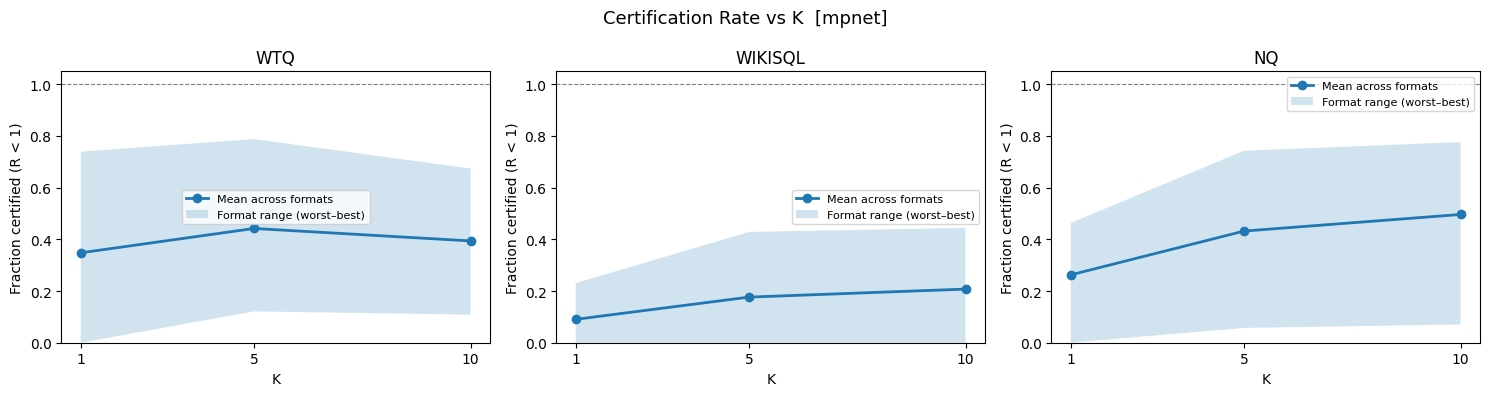

Saved depth monotonicity figure.


In [14]:
# If K_VALUES only has a few levels, we need to recompute for more K values
# For figure purposes, use whichever K values we have

df_certifiable_all = df_base[df_base.Delta > 0].copy()

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 4), sharey=False)
if len(DATASETS) == 1:
    axes = [axes]

for ax, ds in zip(axes, DATASETS):
    g = df_certifiable_all[df_certifiable_all.dataset == ds]
    if g.empty:
        ax.set_title(ds)
        continue

    ks   = sorted(g['K'].unique())
    cert_mean   = [g[g.K==k]['certified'].mean() for k in ks]
    cert_worst  = [g[g.K==k].groupby('fmt')['certified'].mean().min() for k in ks]
    cert_best   = [g[g.K==k].groupby('fmt')['certified'].mean().max() for k in ks]

    ax.plot(ks, cert_mean,  marker='o', label='Mean across formats', lw=2)
    ax.fill_between(ks, cert_worst, cert_best, alpha=0.2, label='Format range (worst–best)')
    ax.axhline(1.0, ls='--', lw=0.8, color='gray')
    ax.set_xlabel('K')
    ax.set_ylabel('Fraction certified (R < 1)')
    ax.set_title(ds)
    ax.legend(fontsize=8)
    ax.set_xticks(ks)
    ax.set_ylim(0, 1.05)

fig.suptitle(f'Certification Rate vs K  [{MODEL_NAME}]', fontsize=13)
plt.tight_layout()
#plt.savefig(f'{RESULTS_DIR}/fig_depth_monotonicity.pdf', bbox_inches='tight')
#plt.savefig(f'{RESULTS_DIR}/fig_depth_monotonicity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved depth monotonicity figure.')

## Figure: R-value Distribution with Retrieval Failure Overlay

CDF of $R_{q,s}^{(K)}$ for K=1 and K=10. The reviewer's prediction: **retrieval failures should concentrate among queries with R near or above 1**. Overlaid dots show actual retrieval failures.

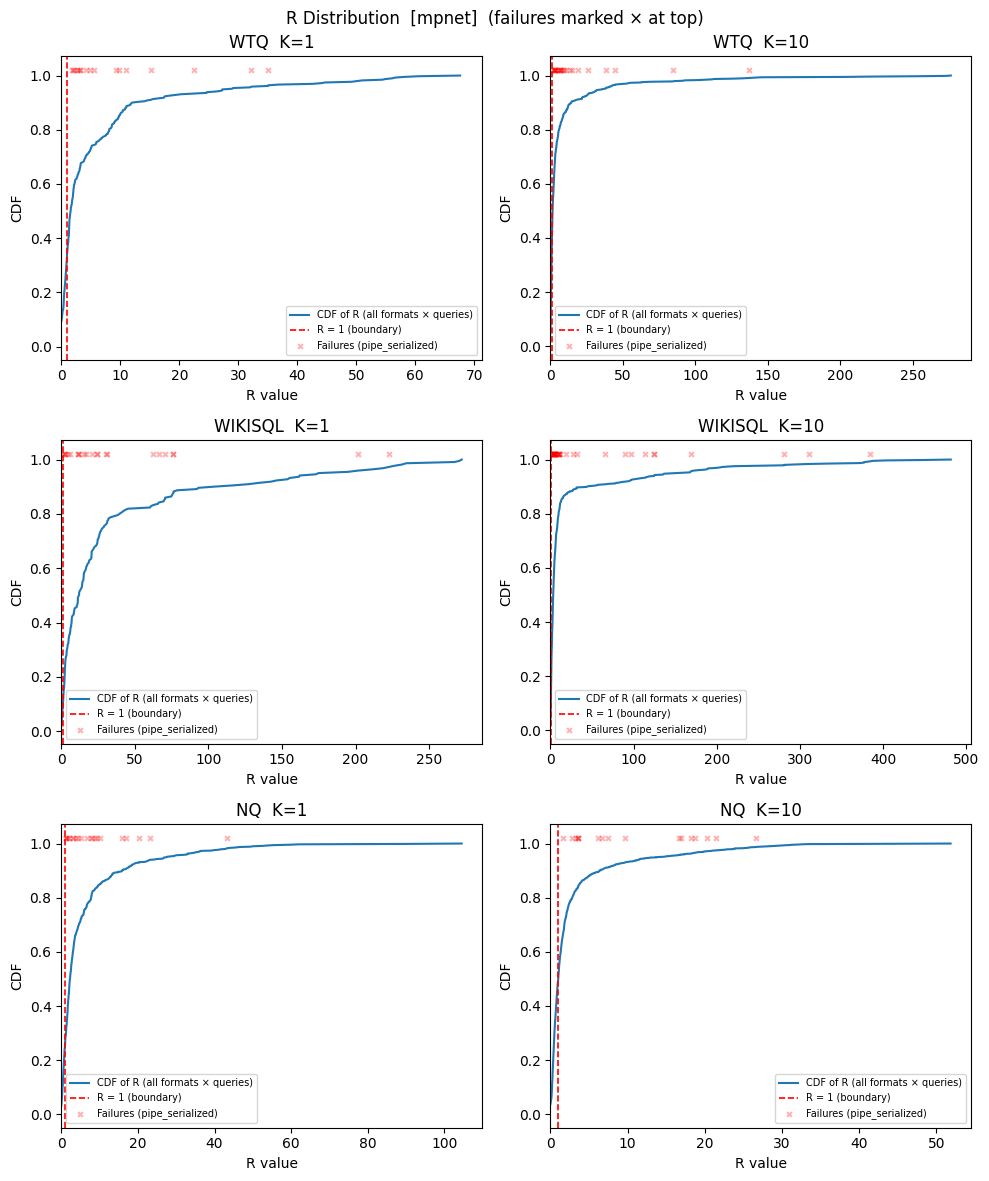

Saved R distribution figure.


In [15]:
# Retrieve actual gold ranks from the pre-computed rank CSVs to determine hit@K
def load_gold_ranks(model_name, dataset, fmt, rank_root=None):
    """Load gold_rank_per_question CSV. Returns dict {question_id: rank}."""
    if rank_root is None:
        rank_root = f'{DATA_ROOT}/retrieval_all/{model_name}_results_rank'
    path = os.path.join(rank_root, dataset, f'chunked_{fmt}_gold_rank_per_question.csv')
    if not os.path.exists(path):
        return {}
    df = pd.read_csv(path)
    return dict(zip(df['question_id'].astype(str), df['rank']))


# Plot for each dataset, one row per dataset, columns for K=1 and K=10
k_plot_values = [k for k in [1, 10] if k in K_VALUES]
if not k_plot_values:
    k_plot_values = K_VALUES[:2]

n_rows  = len(DATASETS)
n_cols  = len(k_plot_values)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)

for row_i, ds in enumerate(DATASETS):
    g_ds = df_certifiable_all[df_certifiable_all.dataset == ds]

    for col_j, K in enumerate(k_plot_values):
        ax = axes[row_i][col_j]
        g  = g_ds[g_ds.K == K]

        if g.empty:
            ax.set_title(f'{ds}  K={K}')
            continue

        R_vals = g['R'].dropna().values
        R_sorted = np.sort(R_vals)
        cdf = np.arange(1, len(R_sorted) + 1) / len(R_sorted)

        ax.plot(R_sorted, cdf, lw=1.5, label='CDF of R (all formats × queries)')
        ax.axvline(1.0, ls='--', lw=1.2, color='red', label='R = 1 (boundary)')

        # Overlay retrieval failures: use gold rank from CSVs
        # For each (qid, fmt) pair in g, check if hit@K
        fmts_available = g['fmt'].unique()[:3]  # use up to 3 formats for clarity
        for fmt in fmts_available:
            ranks = load_gold_ranks(MODEL_NAME, ds, fmt)
            if not ranks:
                continue
            sub = g[g.fmt == fmt].dropna(subset=['R'])
            fail_R   = sub[sub['qid'].map(lambda q: ranks.get(str(q), 9999)) > K]['R'].values
            pass_R   = sub[sub['qid'].map(lambda q: ranks.get(str(q), 9999)) <= K]['R'].values
            if len(fail_R):
                ax.scatter(fail_R, np.ones(len(fail_R)) * 1.02,
                           marker='x', s=12, color='red', alpha=0.3,
                           label=f'Failures ({fmt})' if fmt == fmts_available[0] else '')

        ax.set_xlabel('R value')
        ax.set_ylabel('CDF')
        ax.set_title(f'{ds}  K={K}')
        ax.legend(fontsize=7)
        ax.set_xlim(left=0)

fig.suptitle(f'R Distribution  [{MODEL_NAME}]  (failures marked × at top)', fontsize=12)
plt.tight_layout()
#plt.savefig(f'{RESULTS_DIR}/fig_R_distribution.pdf', bbox_inches='tight')
#plt.savefig(f'{RESULTS_DIR}/fig_R_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved R distribution figure.')

## Figure: Base vs Adapted R Distribution (per dataset, K=1)

Directly visualises whether the adapter shifts the R distribution toward R < 1.

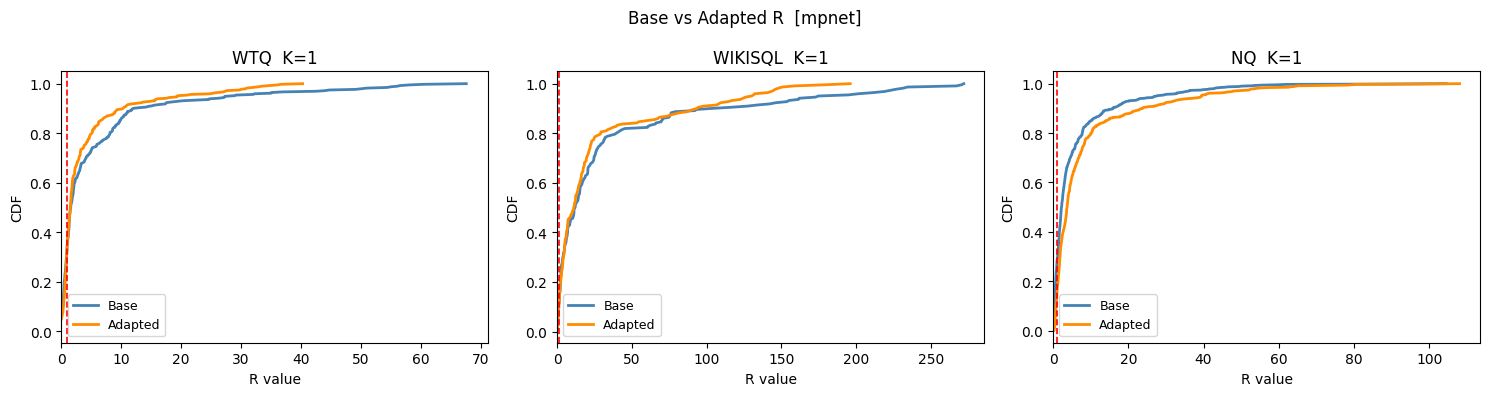

Saved base vs adapted R figure.


In [16]:
if 'adapted' in df_stab.source.values:
    df_adapted_cert = df_stab[(df_stab.source == 'adapted') & (df_stab.Delta > 0)].copy()

    fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 4), squeeze=False)
    axes = axes[0]

    for ax, ds in zip(axes, DATASETS):
        K = 1
        b = df_certifiable_all[(df_certifiable_all.dataset==ds) & (df_certifiable_all.K==K)]['R'].dropna().values
        a = df_adapted_cert[(df_adapted_cert.dataset==ds) & (df_adapted_cert.K==K)]['R'].dropna().values

        if len(b) == 0:
            ax.set_title(ds); continue

        for vals, label, color in [(b, 'Base', 'steelblue'), (a, 'Adapted', 'darkorange')]:
            if len(vals) == 0: continue
            s = np.sort(vals)
            cdf = np.arange(1, len(s)+1) / len(s)
            ax.plot(s, cdf, lw=2, label=label, color=color)

        ax.axvline(1.0, ls='--', lw=1.2, color='red')
        ax.set_xlabel('R value')
        ax.set_ylabel('CDF')
        ax.set_title(f'{ds}  K={K}')
        ax.legend(fontsize=9)
        ax.set_xlim(left=0)

    fig.suptitle(f'Base vs Adapted R  [{MODEL_NAME}]', fontsize=12)
    plt.tight_layout()
    #plt.savefig(f'{RESULTS_DIR}/fig_R_base_vs_adapted.pdf', bbox_inches='tight')
    #plt.savefig(f'{RESULTS_DIR}/fig_R_base_vs_adapted.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved base vs adapted R figure.')
else:
    print('No adapted results to compare.')

## Per-Format Certification Heatmap

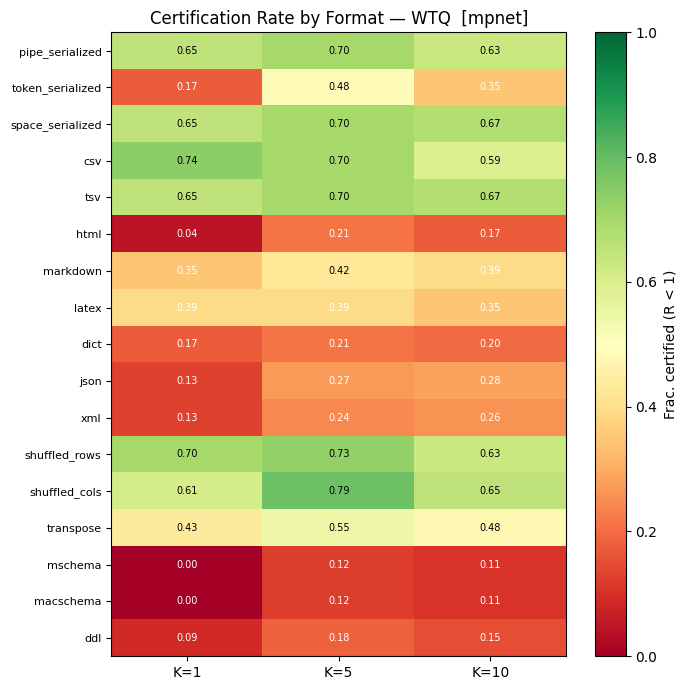

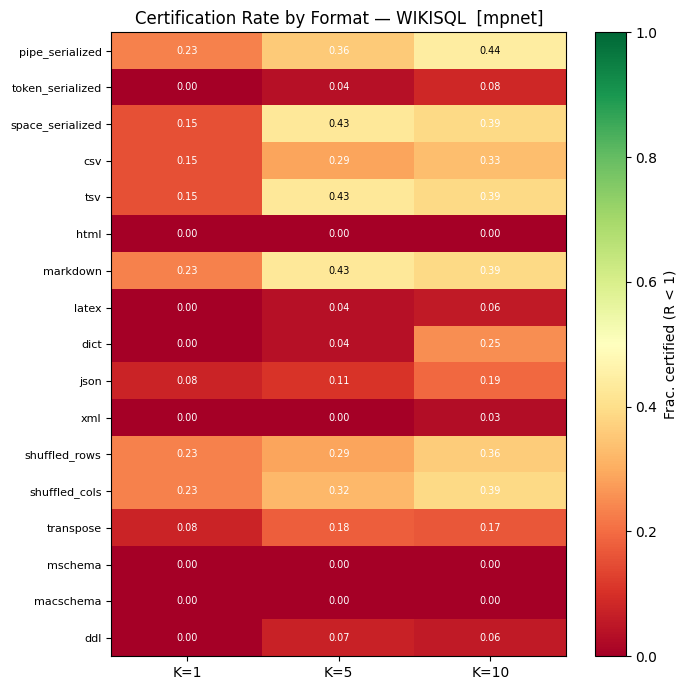

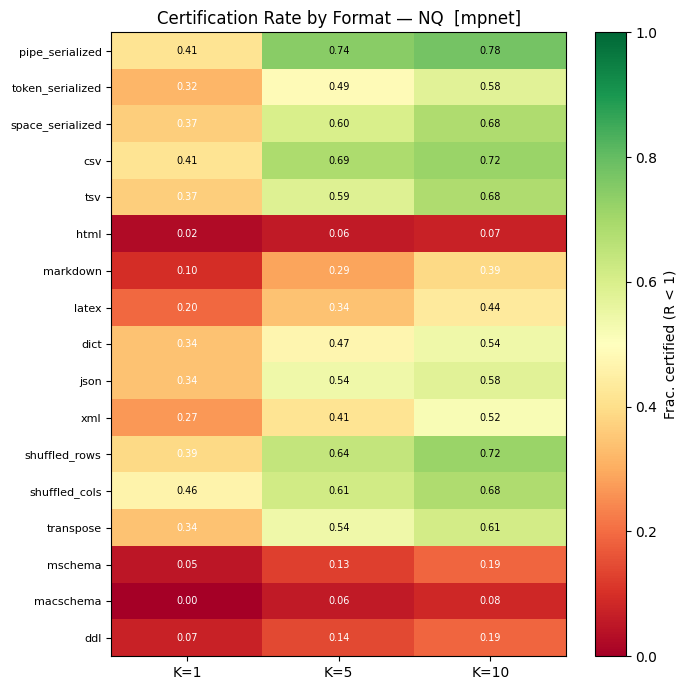

In [17]:
for ds in DATASETS:
    sub = df_certifiable_all[df_certifiable_all.dataset == ds]
    if sub.empty: continue

    pivot = sub.groupby(['fmt', 'K'])['certified'].mean().unstack('K')
    pivot = pivot.reindex(FORMATS_17)  # canonical format order

    fig, ax = plt.subplots(figsize=(4 + len(K_VALUES), 7))
    im = ax.imshow(pivot.values, vmin=0, vmax=1, cmap='RdYlGn', aspect='auto')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f'K={k}' for k in pivot.columns], fontsize=10)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=8)
    ax.set_title(f'Certification Rate by Format — {ds}  [{MODEL_NAME}]')
    plt.colorbar(im, ax=ax, label='Frac. certified (R < 1)')
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                        color='white' if v < 0.4 or v > 0.8 else 'black')
    plt.tight_layout()
    #plt.savefig(f'{RESULTS_DIR}/fig_cert_heatmap_{ds}.pdf', bbox_inches='tight')
    #plt.savefig(f'{RESULTS_DIR}/fig_cert_heatmap_{ds}.png', dpi=150, bbox_inches='tight')
    plt.show()

## Summary Statistics

In [18]:
print('=== Summary ====================================================')
print(f'Model: {MODEL_NAME}   Datasets: {DATASETS}')
print(f'Total stability rows: {len(df_stab)}')
print()

for source in df_stab.source.unique():
    d = df_stab[(df_stab.source == source) & (df_stab.Delta > 0)]
    print(f'--- Source: {source} ---')
    for (ds, K), g in d.groupby(['dataset', 'K']):
        cert_rate = g['certified'].mean()
        med_R = g['R'].median()
        print(f'  {ds} K={K}: cert={cert_rate:.3f}  median_R={med_R:.3f}  N={len(g)}')
    print()

=== Summary ====================================================
Model: mpnet   Datasets: ['WTQ', 'WIKISQL', 'NQ']
Total stability rows: 30600

--- Source: base ---
  NQ K=1: cert=0.263  median_R=2.264  N=697
  NQ K=5: cert=0.432  median_R=1.242  N=1190
  NQ K=10: cert=0.496  median_R=1.004  N=1445
  WIKISQL K=1: cert=0.090  median_R=12.103  N=221
  WIKISQL K=5: cert=0.176  median_R=3.675  N=476
  WIKISQL K=10: cert=0.208  median_R=3.307  N=612
  WTQ K=1: cert=0.348  median_R=1.589  N=391
  WTQ K=5: cert=0.442  median_R=1.230  N=561
  WTQ K=10: cert=0.394  median_R=1.461  N=782

--- Source: adapted ---
  NQ K=1: cert=0.135  median_R=3.745  N=697
  NQ K=5: cert=0.260  median_R=1.931  N=1190
  NQ K=10: cert=0.308  median_R=1.444  N=1445
  WIKISQL K=1: cert=0.090  median_R=11.208  N=221
  WIKISQL K=5: cert=0.153  median_R=3.170  N=476
  WIKISQL K=10: cert=0.191  median_R=2.637  N=612
  WTQ K=1: cert=0.348  median_R=1.517  N=391
  WTQ K=5: cert=0.483  median_R=1.029  N=561
  WTQ K=10: cert